Confusion Matrix:
 [[64  4]
 [ 3 29]]
Accuracy: 0.93


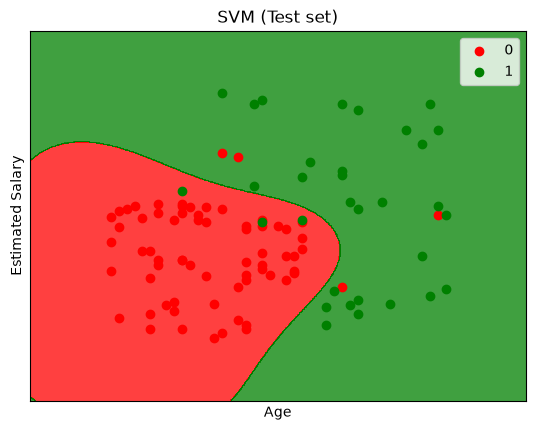

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score

df = pd.read_csv(r"C:\Users\super\Downloads\Social_Network_Ads.csv")
X, y = df.iloc[:, [2, 3]].values, df.iloc[:, 4].values

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

model = SVC(kernel='rbf', random_state=0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

X1, X2 = np.meshgrid(
    np.arange(x_test[:,0].min()-1, x_test[:,0].max()+1, 0.01),
    np.arange(x_test[:,1].min()-1, x_test[:,1].max()+1, 0.01))

cmap = ListedColormap(('red', 'green'))
plt.contourf(X1, X2, model.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape),
             alpha=0.75, cmap=cmap)

for i, j in enumerate(np.unique(y_test)):
    plt.scatter(x_test[y_test==j, 0], x_test[y_test==j, 1], color=cmap(i), label=j)

plt.title('SVM (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.xticks(())
plt.yticks(())
plt.legend()
plt.show()